# Ejemplos ACP en R
---

## Alimentación

In [2]:
library(readxl)      # Para leer archivos Excel (.xlsx)
library(dplyr)       # Para manipular datos (seleccionar, filtrar, agrupar, etc.)
library(ggplot2)     # Para crear gráficos elegantes
library(rstudioapi)  # Para interactuar con el entorno de RStudio
library(lattice)     # Para gráficos multivariados (menos usado que ggplot2)
library(corrr)
library(ggcorrplot)
library(FactoMineR)  # Módulo para ACP
library(factoextra)

In [3]:
#install.packages("factoextra")

In [4]:
data <- read_excel('/Users/ppando/Materias/cs-datos/especializacion/data/Alimentacion.xlsx')

In [5]:
View(data)

País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
Bélgica,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
Checosl,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
Dinamarca,10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4
AlemaniaE,8.4,11.6,3.7,11.1,5.4,24.6,6.5,0.8,3.6
Finlandia,9.5,4.9,2.7,33.7,5.8,26.3,5.1,1.0,1.4
Francia,18.0,9.9,3.3,19.5,5.7,28.1,4.8,2.4,6.5


In [6]:
head(data)

País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
Bélgica,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
Checosl,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
Dinamarca,10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4


In [7]:
dim(data)

[1] 25 10

In [8]:
str(data)

tibble [25 × 10] (S3: tbl_df/tbl/data.frame)
 $ País            : chr [1:25] "Albania" "Austria" "Bélgica" "Bulgaria" ...
 $ CarneVacuna     : num [1:25] 10.1 8.9 13.5 7.8 9.7 10.6 8.4 9.5 18 10.2 ...
 $ CarneCerdo      : num [1:25] 1.4 14 9.3 6 11.4 10.8 11.6 4.9 9.9 3 ...
 $ Huevos          : num [1:25] 0.5 4.3 4.1 1.6 2.8 3.7 3.7 2.7 3.3 2.8 ...
 $ Leche           : num [1:25] 8.9 19.9 17.5 8.3 12.5 25 11.1 33.7 19.5 17.6 ...
 $ Pescado         : num [1:25] 0.2 2.1 4.5 1.2 2 9.9 5.4 5.8 5.7 5.9 ...
 $ Cereal          : num [1:25] 42.3 28 26.6 56.7 34.3 21.9 24.6 26.3 28.1 41.7 ...
 $ Embutidos       : num [1:25] 0.6 3.6 5.7 1.1 5 4.8 6.5 5.1 4.8 2.2 ...
 $ FrutosSecos     : num [1:25] 5.5 1.3 2.1 3.7 1.1 0.7 0.8 1 2.4 7.8 ...
 $ FrutasyVegetales: num [1:25] 1.7 4.3 4 4.2 4 2.4 3.6 1.4 6.5 6.5 ...


In [9]:
# verificar valores faltantes
colSums(is.na(data))

País      CarneVacuna       CarneCerdo           Huevos 
               0                0                0                0 
           Leche          Pescado           Cereal        Embutidos 
               0                0                0                0 
     FrutosSecos FrutasyVegetales 
               0                0

In [10]:
# seleccionar columnas numericas
num_data <- data[, sapply(data, is.numeric)]
head(num_data)

CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4


In [11]:
# normalizar los datos
data_norm <- scale(num_data)
head(data_norm)

CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
0.08126490,-1.7584889,-2.1796385,-1.15573814,-1.20028213,0.9159176,-2.2495772,1.2227536,-1.35040507
-0.27725673,1.6523731,1.2204544,0.39237676,-0.64187467,-0.3870690,-0.4136872,-0.8923886,0.09091397
1.09707621,0.3800675,1.0415022,0.05460623,0.06348211,-0.5146342,0.8714358,-0.4895043,-0.07539207
-0.60590157,-0.5132535,-1.1954011,-1.24018077,-0.90638347,2.2280161,-1.9435955,0.3162641,0.03547862
-0.03824231,0.9485445,-0.1216875,-0.64908235,-0.67126454,0.1869740,0.4430614,-0.9931096,-0.07539207
0.23064892,0.7861225,0.6835976,1.11013912,1.65053488,-0.9428885,0.3206688,-1.1945517,-0.96235764


In [12]:
# Compute the correlation matrix
corr_matrix <- cor(data_norm)
corr_matrix

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
CarneVacuna,1.00000000,0.1530027,0.58560895,0.5029311,0.06095745,-0.49987746,0.13542594,-0.3494486,-0.07422123
CarneCerdo,0.15300271,1.0000000,0.62040916,0.2814839,-0.23400923,-0.41379691,0.31377205,-0.6349618,-0.06131670
Huevos,0.58560895,0.6204092,1.00000000,0.5755331,0.06557136,-0.71243682,0.45223071,-0.5597810,-0.04551755
Leche,0.50293110,0.2814839,0.57553312,1.0000000,0.13788370,-0.59273662,0.22241118,-0.6210875,-0.40836414
Pescado,0.06095745,-0.2340092,0.06557136,0.1378837,1.00000000,-0.52423080,0.40385286,-0.1471529,0.26613865
Cereal,-0.49987746,-0.4137969,-0.71243682,-0.5927366,-0.52423080,1.00000000,-0.53326231,0.6509973,0.04654808
Embutidos,0.13542594,0.3137721,0.45223071,0.2224112,0.40385286,-0.53326231,1.00000000,-0.4743116,0.08440956
FrutosSecos,-0.34944855,-0.6349618,-0.55978097,-0.6210875,-0.14715294,0.65099727,-0.47431155,1.0000000,0.37496971
FrutasyVegetales,-0.07422123,-0.0613167,-0.04551755,-0.4083641,0.26613865,0.04654808,0.08440956,0.3749697,1.00000000


In [13]:
# Compute the correlation matrix (da lo mismo sin normalizar!!)
corr_matrix_corr <- cor(num_data)
corr_matrix_corr

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,FrutasyVegetales
CarneVacuna,1.00000000,0.1530027,0.58560895,0.5029311,0.06095745,-0.49987746,0.13542594,-0.3494486,-0.07422123
CarneCerdo,0.15300271,1.0000000,0.62040916,0.2814839,-0.23400923,-0.41379691,0.31377205,-0.6349618,-0.06131670
Huevos,0.58560895,0.6204092,1.00000000,0.5755331,0.06557136,-0.71243682,0.45223071,-0.5597810,-0.04551755
Leche,0.50293110,0.2814839,0.57553312,1.0000000,0.13788370,-0.59273662,0.22241118,-0.6210875,-0.40836414
Pescado,0.06095745,-0.2340092,0.06557136,0.1378837,1.00000000,-0.52423080,0.40385286,-0.1471529,0.26613865
Cereal,-0.49987746,-0.4137969,-0.71243682,-0.5927366,-0.52423080,1.00000000,-0.53326231,0.6509973,0.04654808
Embutidos,0.13542594,0.3137721,0.45223071,0.2224112,0.40385286,-0.53326231,1.00000000,-0.4743116,0.08440956
FrutosSecos,-0.34944855,-0.6349618,-0.55978097,-0.6210875,-0.14715294,0.65099727,-0.47431155,1.0000000,0.37496971
FrutasyVegetales,-0.07422123,-0.0613167,-0.04551755,-0.4083641,0.26613865,0.04654808,0.08440956,0.3749697,1.00000000


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ggcorrplot package.
  Please report the issue at <https://github.com/kassambara/ggcorrplot/issues>.”


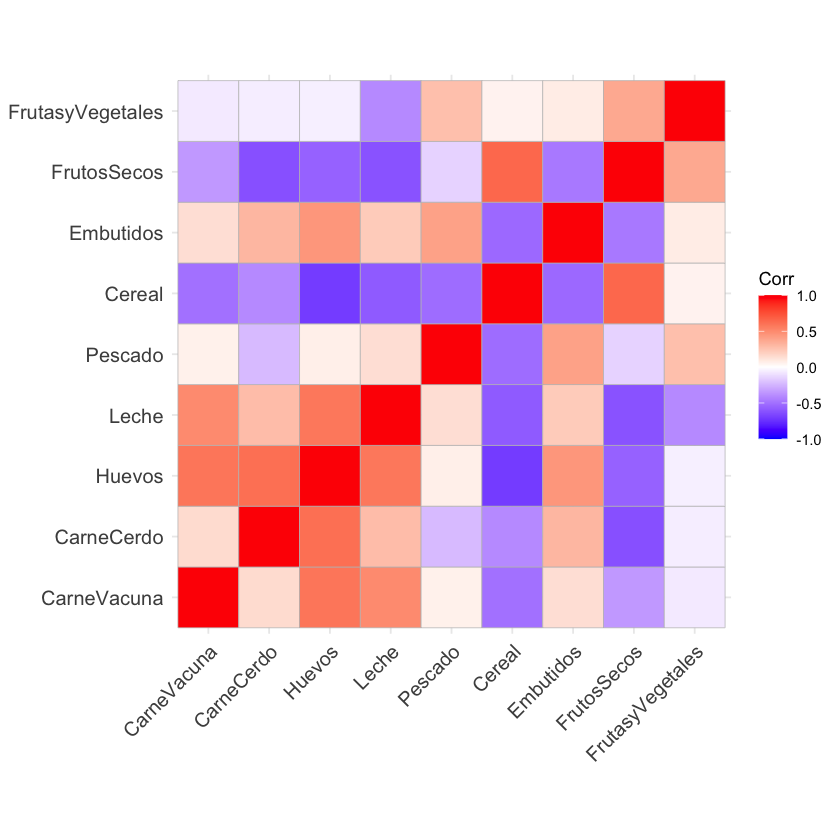

In [14]:
ggcorrplot(corr_matrix) # muestra solo la mitad un rectangulo que repite valores en espejo

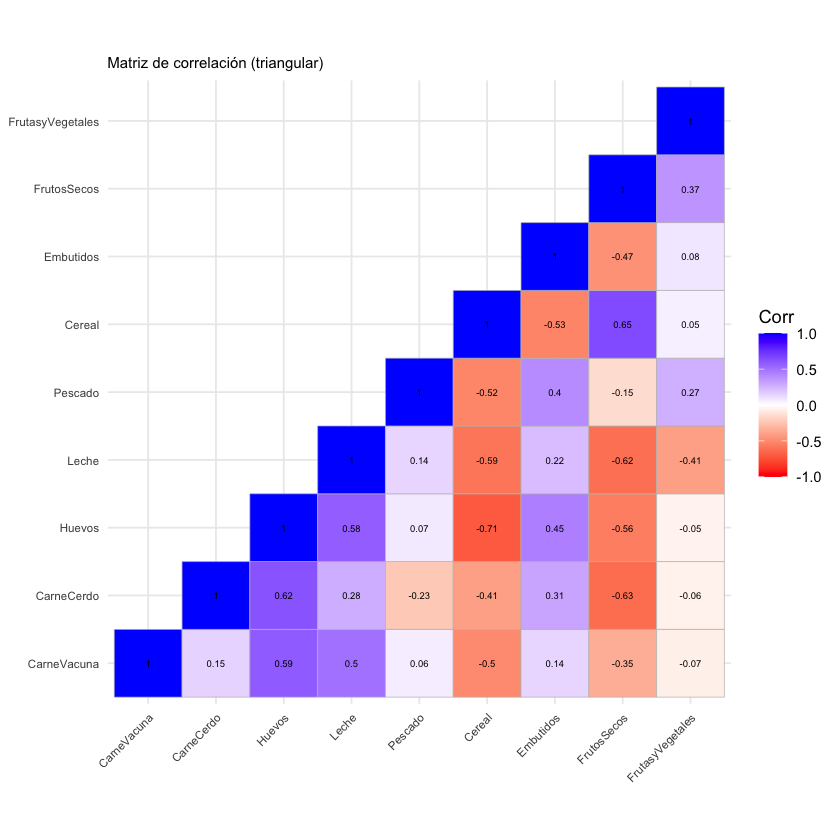

In [15]:
ggcorrplot(corr_matrix,
           method = "square",
           type = "lower",      # muestra solo la mitad inferior, "upper" para superior
           lab = TRUE,          # muestra los valores numéricos
           lab_size = 2,
           colors = c("red", "white", "blue"),
           show.diag = TRUE,
           title = "Matriz de correlación (triangular)") +
  theme(
    axis.text.x = element_text(size = 7),     # tamaño de texto en eje X
    axis.text.y = element_text(size = 7),     # tamaño de texto en eje Y
    plot.title = element_text(size = 9)      # tamaño del título
  )

In [16]:
rownames <- data$País
rownames

[1] "Albania"    "Austria"    "Bélgica"    "Bulgaria"   "Checosl"   
 [6] "Dinamarca"  "AlemaniaE"  "Finlandia"  "Francia"    "Grecia"    
[11] "Hungría"    "Irlanda"    "Italia"     "P.Bajos"    "Noruega"   
[16] "Polonia"    "Portugal"   "Rumania"    "España"     "Suecia"    
[21] "Suiza"      "Inglaterra" "Rusia"      "AlemaniaO"  "Yugoslavia"

In [17]:
num_data <- data[, 2:10]
res.pca <- PCA(num_data,  scale= TRUE)

In [ ]:
# Eigenvalores (varianza explicada)
res.pca$eig

In [18]:
# Coordenadas de las variables
res.pca$var$coord

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
CarneVacuna,0.6057056,-0.07192736,-0.31604009,0.631652227,0.21940932
CarneCerdo,0.6216121,-0.30285749,0.66260104,-0.036144004,-0.20442938
Huevos,0.8540434,-0.04518280,0.19278949,0.305982733,0.05387873
Leche,0.7560622,-0.23602830,-0.40958221,-0.003242188,-0.13649306
Pescado,0.2715180,0.82706958,-0.34120473,-0.211002952,-0.19752735
Cereal,-0.8761911,-0.29855059,0.10186779,-0.006061851,0.16220583
Embutidos,0.5949735,0.45114790,0.25804812,-0.328964239,0.50123965
FrutosSecos,-0.8413450,0.18324705,-0.05776175,0.322713744,0.10252418
FrutasyVegetales,-0.2210174,0.68561064,0.43283909,0.451460378,-0.15903812


In [19]:
# Coordenadas de los individuos (observaciones-> paises en este caso)
res.pca$ind$coord

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
1,-3.5572381,-1.66410153,-1.797551168,0.2343937,0.02373348
2,1.4520059,-1.06270224,1.365390393,0.1715636,-0.95269493
3,1.6554798,0.16278449,0.220999548,0.5314638,0.77066090
4,-3.1987084,-1.32789455,0.154409266,0.2186061,-0.49474117
5,0.3781039,-0.61509588,1.220603019,-0.4735497,0.26211969
6,2.4140424,0.29133192,-0.767775590,-0.9872885,-0.76794882
7,1.4515379,0.45958638,1.329399490,-1.1593857,0.43166418
8,1.5961042,-0.60829255,-2.091769672,-1.4444931,0.03797025
9,1.5186657,0.80155997,0.001921431,1.9978218,0.25562334
10,-2.2858842,1.02170143,-0.900803315,1.8313202,-0.41332823


In [20]:
# Contribución de cada variable a los componentes->ver las mas altas
res.pca$var$contrib 

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
CarneVacuna,9.157244,0.3164249,8.8553603,41.793191158,10.3787116
CarneCerdo,9.644517,5.6099503,38.9247763,0.136842815,9.0098990
Huevos,18.205455,0.1248616,3.2952517,9.807161107,0.6258468
Leche,14.267790,3.4073013,14.8731882,0.001101098,4.0165616
Pescado,1.840089,41.8375731,10.3217180,4.663656241,8.4117778
Cereal,19.161931,5.4515283,0.9200167,0.003849107,5.6723915
Embutidos,8.835618,12.4485929,5.9036866,11.335660956,54.1656727
FrutosSecos,17.668101,2.0537917,0.2958030,10.908986232,2.2661356
FrutasyVegetales,1.219255,28.7499760,16.6101992,21.349551287,5.4530032


In [21]:
# Calidad de representación (coseno cuadrado o comunalidad)        
res.pca$var$cos2    

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
CarneVacuna,0.36687927,0.005173545,0.09988134,3.989845e-01,0.048140449
CarneCerdo,0.38640155,0.091722657,0.43904014,1.306389e-03,0.041791371
Huevos,0.72939019,0.002041486,0.03716779,9.362543e-02,0.002902918
Leche,0.57163009,0.055709357,0.16775759,1.051178e-05,0.018630355
Pescado,0.07372203,0.684044088,0.11642067,4.452225e-02,0.039017055
Cereal,0.76771081,0.089132457,0.01037705,3.674604e-05,0.026310730
Embutidos,0.35399350,0.203534426,0.06658883,1.082175e-01,0.251241187
FrutosSecos,0.70786143,0.033579483,0.00333642,1.041442e-01,0.010511207
FrutasyVegetales,0.04884870,0.470061949,0.18734968,2.038165e-01,0.025293123


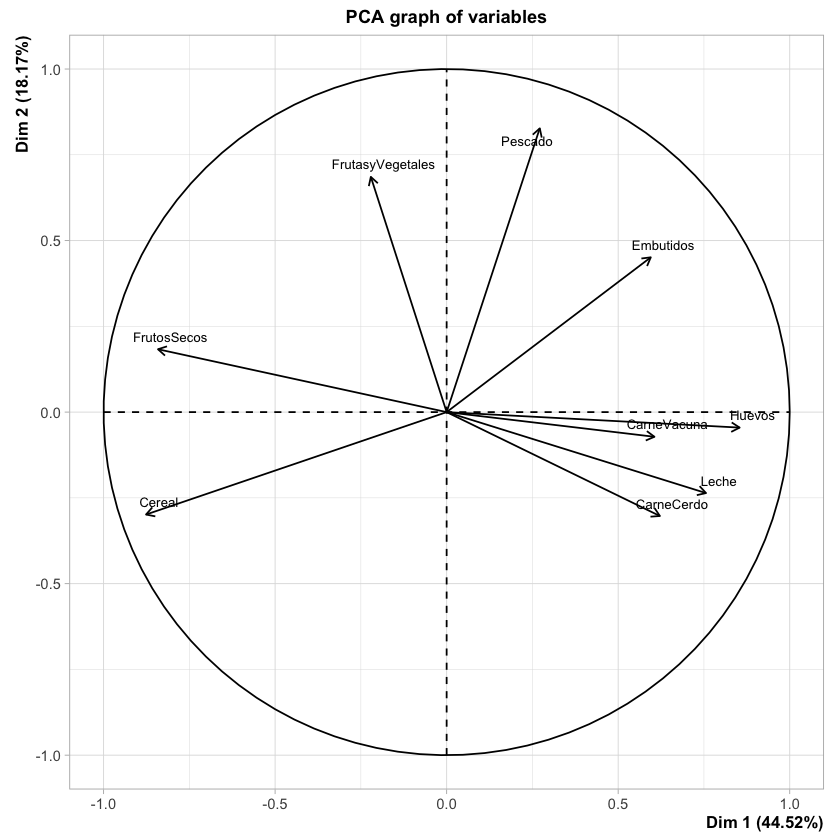

In [22]:
plot(res.pca, choix = "var", axes = c(1, 2), cex = 0.7)  # reduce el tamaño de texto

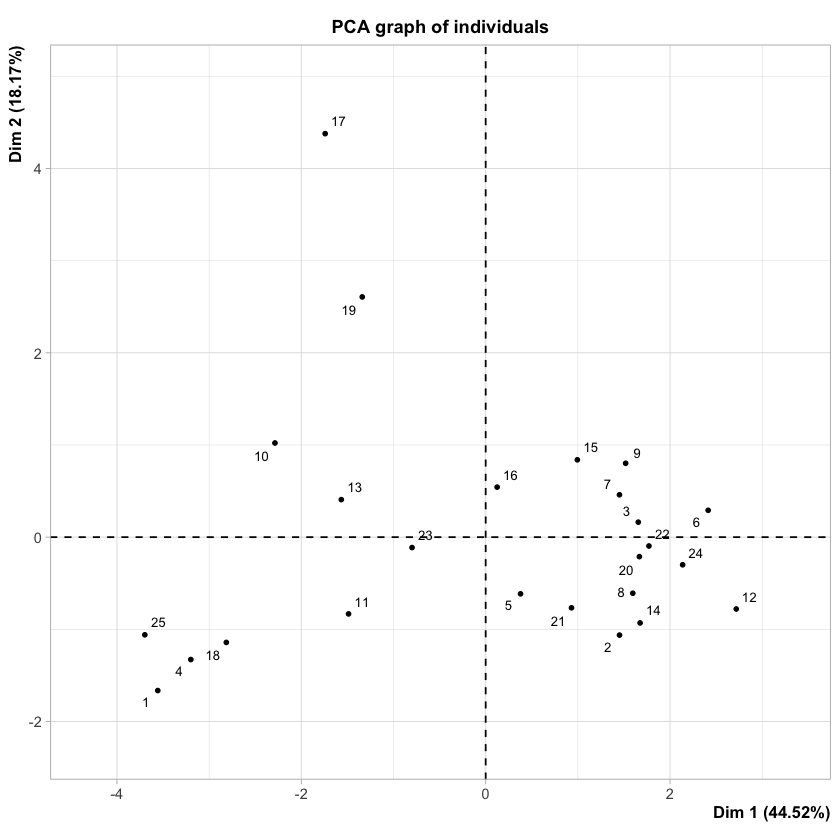

In [26]:
plot(res.pca, 
     choix = "ind",       # "ind" indica que querés graficar los individuos
     axes = c(1, 2),      # selecciona las dos primeras componentes
     cex = 0.7)           # reduce el tamaño de las etiquetas

## Celtis

In [28]:
celtis <- read.table("/Users/ppando/Materias/cs-datos/especializacion/data/Celtis.txt", header = T)

In [29]:
round(cor(celtis), 2)

,diam,az,pulpa,sem,pulpa.sem
diam,1.00,-0.33,0.99,0.45,0.56
az,-0.33,1.00,-0.37,0.20,-0.49
pulpa,0.99,-0.37,1.00,0.34,0.65
sem,0.45,0.20,0.34,1.00,-0.43
pulpa.sem,0.56,-0.49,0.65,-0.43,1.00


In [30]:
pca <- PCA(celtis, scale.unit = TRUE)

In [ ]:
round(pca$eig, 2)

Warning message in geom_bar(stat = "identity", fill = barfill, color = barcolor, :
“Ignoring empty aesthetic: `width`.”


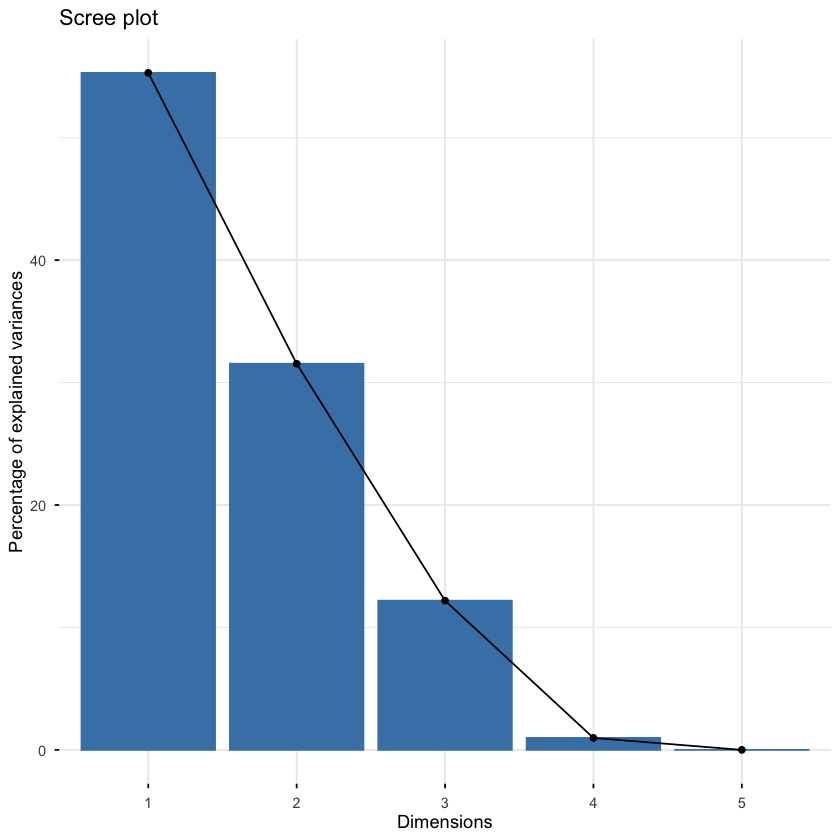

In [31]:
fviz_eig(pca)

In [32]:
round(pca$var$coord, 3)

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
diam,0.939,0.328,0.085,-0.063,-0.002
az,-0.575,0.465,0.673,-0.004,0.000
pulpa,0.965,0.220,0.117,-0.082,0.002
sem,0.174,0.953,-0.213,0.127,0.000
pulpa.sem,0.769,-0.544,0.300,0.148,0.000


In [33]:
round(pca$var$contrib, 3)

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
diam,31.874,6.823,1.184,7.998,52.120
az,11.966,13.736,74.271,0.027,0.000
pulpa,33.667,3.080,2.258,13.924,47.071
sem,1.093,57.587,7.471,33.040,0.809
pulpa.sem,21.400,18.774,14.817,45.010,0.000


In [34]:
round(pca$var$cos2, 3)

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
diam,0.881,0.108,0.007,0.004,0
az,0.331,0.217,0.453,0.000,0
pulpa,0.931,0.049,0.014,0.007,0
sem,0.030,0.908,0.046,0.016,0
pulpa.sem,0.592,0.296,0.090,0.022,0


In [35]:
# autovalores
colSums(pca$var$cos2[, ])

Dim.1        Dim.2        Dim.3        Dim.4        Dim.5 
2.764896e+00 1.576949e+00 6.092976e-01 4.885245e-02 4.909906e-06

In [36]:
colSums(pca$var$contrib[, ])

Dim.1 Dim.2 Dim.3 Dim.4 Dim.5 
  100   100   100   100   100

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>.”


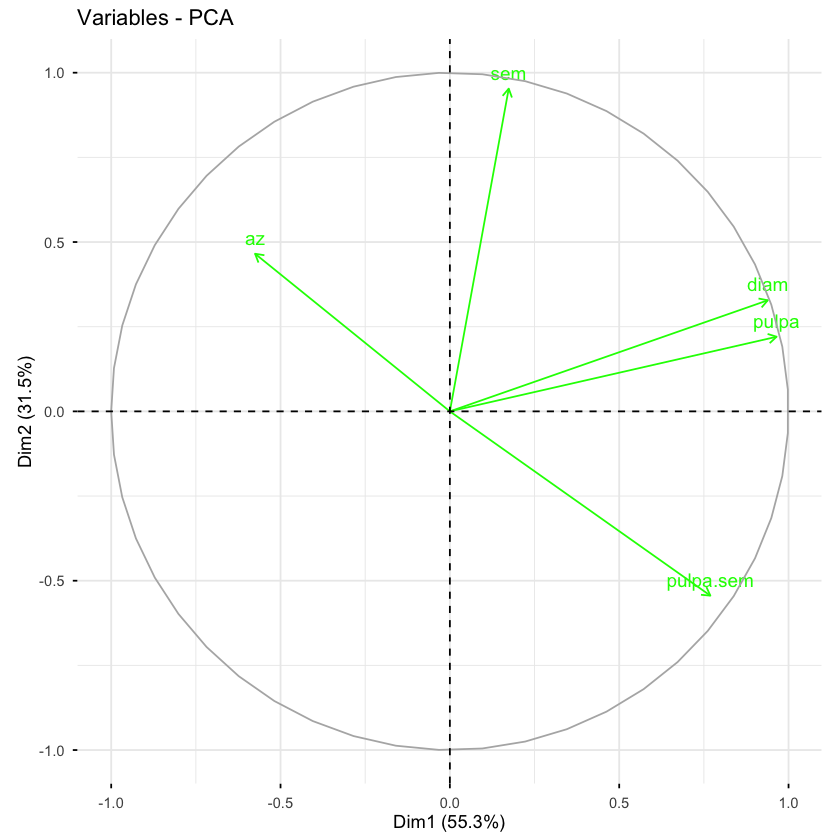

In [37]:
fviz_pca_var(pca, col.var = "green")

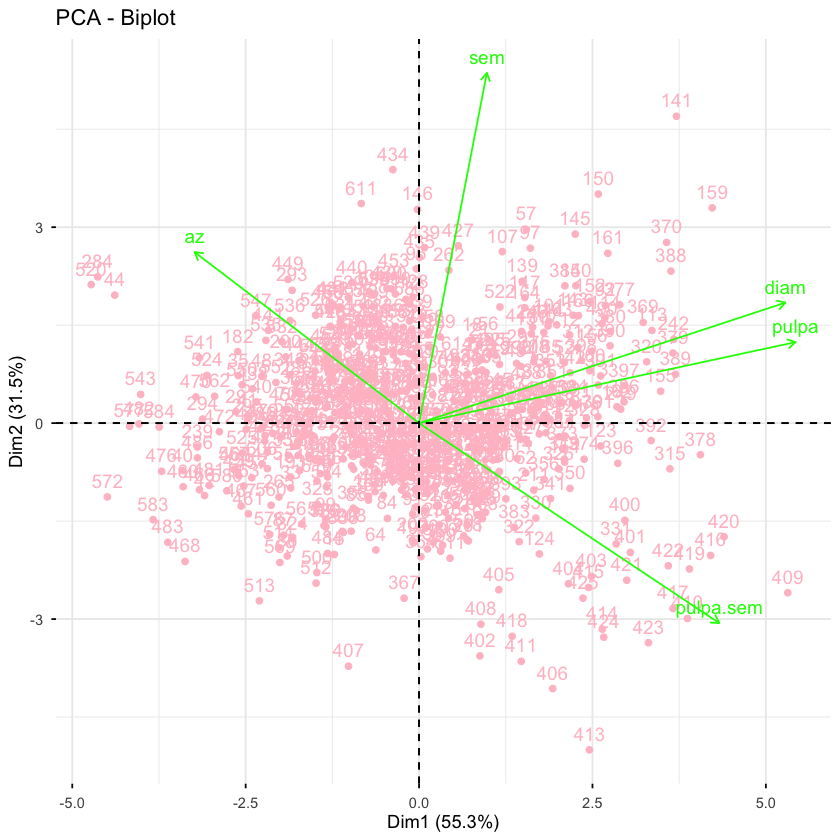

In [38]:
fviz_pca_biplot(pca, col.ind = "pink", col.var = "green")